# 2016 — YOLO: Real-Time Object Detection

**Papers:** Joseph Redmon, Santosh Divvala, Ross Girshick & Ali Farhadi, *"You Only Look Once: Unified, Real-Time Object Detection"*, CVPR (2016). The two-stage line it competed with: R-CNN (Girshick et al., 2014), Fast R-CNN (2015), Faster R-CNN (Ren, He, Girshick & Sun, 2015).

Classification says *what* is in an image. **Detection** says what, **where** (a bounding box) and **how many**. Until 2015, detectors were pipelines: propose ~2,000 candidate regions, then classify each with a CNN. Faster R-CNN learned the proposals with a region proposal network, but still ran two stages.

**YOLO** turned detection into a single regression problem. Divide the image into an $S\times S$ grid. The cell containing an object's centre is responsible for it and predicts, in one forward pass:
- an **objectness** score (is there an object centred here?)
- the **box**: centre offset within the cell, width and height
- **class** probabilities

At test time, keep confident boxes and remove duplicates with **non-maximum suppression (NMS)**. YOLO ran at 45 frames per second in 2016; its descendants (YOLOv3–v11, DETR's set prediction, RT-DETR) are still the standard for real-time detection.

**Data:** synthetic 64×64 scenes with 1–4 shapes (square, disc, triangle) of random size, position, brightness and background noise, generated on the fly, so no download is needed.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
IMG, S, CLASSES = 64, 8, ["square", "disc", "triangle"]
CELL = IMG // S
yy, xx = torch.meshgrid(torch.arange(IMG), torch.arange(IMG), indexing="ij")

def scene(rng):
    img = torch.rand(IMG, IMG) * 0.25
    boxes = []
    for _ in range(rng.integers(1, 5)):
        c = int(rng.integers(3)); w = int(rng.integers(10, 26)); h = w if c != 2 else int(rng.integers(10, 26))
        x0, y0 = int(rng.integers(0, IMG - w)), int(rng.integers(0, IMG - h))
        if c == 0: m = (xx >= x0) & (xx < x0 + w) & (yy >= y0) & (yy < y0 + h)
        elif c == 1: m = ((xx - x0 - w / 2) ** 2 + (yy - y0 - h / 2) ** 2) <= (w / 2) ** 2
        else: m = (yy >= y0) & (yy < y0 + h) & ((xx - x0 - w / 2).abs() <= (yy - y0 + 1) * w / (2 * h))
        img[m] = 0.5 + 0.5 * float(rng.random())
        boxes.append((c, x0 + w / 2, y0 + h / 2, w, h))                       # class, centre x, centre y, width, height
    return img, boxes

def batch(n, rng):
    imgs, targets, all_boxes = [], torch.zeros(n, S, S, 5 + len(CLASSES)), []
    for i in range(n):
        img, boxes = scene(rng); imgs.append(img); all_boxes.append(boxes)
        for c, cx, cy, w, h in boxes:
            gi, gj = min(int(cx // CELL), S - 1), min(int(cy // CELL), S - 1)
            targets[i, gj, gi, :5] = torch.tensor([1.0, cx / CELL - gi, cy / CELL - gj, math.sqrt(w / IMG), math.sqrt(h / IMG)])
            targets[i, gj, gi, 5 + c] = 1.0
    return torch.stack(imgs)[:, None], targets, all_boxes

## The network and the YOLO loss
A small CNN maps 64×64 → an 8×8 grid of predictions. As in the paper, width and height are predicted as square roots (so an error on a small box costs more than the same error on a large one), and box errors count only in cells that contain an object. YOLOv1 predicted two boxes per cell; we use one.

In [3]:
class TinyYOLO(nn.Module):
    def __init__(self):
        super().__init__()
        c = lambda i, o: [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.LeakyReLU(0.1)]
        self.net = nn.Sequential(*c(1, 32), nn.MaxPool2d(2), *c(32, 64), nn.MaxPool2d(2), *c(64, 128), nn.MaxPool2d(2),
                                 *c(128, 128), *c(128, 128), nn.Conv2d(128, 5 + len(CLASSES), 1))
    def forward(self, x): return self.net(x).permute(0, 2, 3, 1)                # (B, S, S, 5 + C)

def yolo_loss(p, t, l_coord=5.0, l_noobj=0.5):
    obj = t[..., 0]
    l_obj = F.binary_cross_entropy_with_logits(p[..., 0], obj, weight=obj + l_noobj * (1 - obj), reduction="sum")
    xy = F.mse_loss(torch.sigmoid(p[..., 1:3]), t[..., 1:3], reduction="none").sum(-1)
    wh = F.mse_loss(p[..., 3:5], t[..., 3:5], reduction="none").sum(-1)
    cls = F.cross_entropy(p[..., 5:].reshape(-1, len(CLASSES)), t[..., 5:].argmax(-1).reshape(-1), reduction="none").view_as(obj)
    return (l_obj + l_coord * ((xy + wh) * obj).sum() + (cls * obj).sum()) / len(p)

seed_everything(0); rng = np.random.default_rng(0)
model = TinyYOLO().to(device); opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
steps = 2500; sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=steps, pct_start=0.1); losses = []; t0 = time.time()
for s in range(steps):
    x, t, _ = batch(64, rng)
    loss = yolo_loss(model(x.to(device)), t.to(device)); opt.zero_grad(); loss.backward(); opt.step(); sched.step(); losses.append(loss.item())
print(f"trained {steps} steps in {time.time() - t0:.0f}s; final loss {np.mean(losses[-100:]):.3f}")

trained 2500 steps in 114s; final loss 0.682


## Decoding, IoU and non-maximum suppression

In [4]:
def iou(a, b):
    """IoU between boxes in (x1, y1, x2, y2) format; a: (N, 4), b: (M, 4) → (N, M)."""
    lt, rb = torch.max(a[:, None, :2], b[None, :, :2]), torch.min(a[:, None, 2:], b[None, :, 2:])
    inter = (rb - lt).clamp(min=0).prod(-1)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None] - inter)

def decode(p, conf=0.3, nms_iou=0.5):
    """One image's grid output → list of (class, score, box) after per-class NMS."""
    gj, gi = torch.meshgrid(torch.arange(S), torch.arange(S), indexing="ij")
    obj = torch.sigmoid(p[..., 0]); cls_p = F.softmax(p[..., 5:], -1)
    score, cls = (obj[..., None] * cls_p).max(-1)
    cx = (gi + torch.sigmoid(p[..., 1])) * CELL; cy = (gj + torch.sigmoid(p[..., 2])) * CELL
    w, h = p[..., 3].clamp(min=0) ** 2 * IMG, p[..., 4].clamp(min=0) ** 2 * IMG
    boxes = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1).view(-1, 4)
    score, cls = score.flatten(), cls.flatten()
    keep = score > conf; boxes, score, cls = boxes[keep], score[keep], cls[keep]
    out = []
    for c in cls.unique():
        b, s_ = boxes[cls == c], score[cls == c]; order = s_.argsort(descending=True); b, s_ = b[order], s_[order]
        alive = torch.ones(len(b), dtype=torch.bool)
        for i in range(len(b)):                                               # greedy NMS
            if not alive[i]: continue
            out.append((int(c), s_[i].item(), b[i]))
            alive &= ~(iou(b[i:i + 1], b)[0] > nms_iou) | (torch.arange(len(b)) <= i)
            alive[i] = False
    return out

def average_precision(dets, gts, c, thr=0.5):
    """VOC-style AP for class c: rank detections by score, match each to an unused ground truth with IoU ≥ thr."""
    records, n_gt = [], 0
    for d, g in zip(dets, gts):
        gb = torch.tensor([[cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2] for k, cx, cy, w, h in g if k == c]).view(-1, 4)
        n_gt += len(gb); used = torch.zeros(len(gb), dtype=torch.bool)
        for k, s_, b in sorted([x for x in d if x[0] == c], key=lambda x: -x[1]):
            ok = False
            if len(gb):
                ious = iou(b[None], gb)[0]; ious[used] = 0; j = ious.argmax()
                if ious[j] >= thr: used[j] = True; ok = True
            records.append((s_, ok))
    records.sort(key=lambda r: -r[0]); tp = np.cumsum([r[1] for r in records]); fp = np.cumsum([not r[1] for r in records])
    rec, prec = tp / max(n_gt, 1), tp / np.maximum(tp + fp, 1)
    return sum(max(prec[rec >= r], default=0) for r in np.linspace(0, 1, 11)) / 11       # 11-point interpolated AP

model.eval(); rng_test = np.random.default_rng(999)
x, _, gts = batch(500, rng_test)
with torch.no_grad(): preds = model(x.to(device)).cpu()
dets = [decode(p) for p in preds]
aps = [average_precision(dets, gts, c) for c in range(len(CLASSES))]
for c, ap in zip(CLASSES, aps): print(f"AP@0.5 {c:9s} {ap:.3f}")
print(f"mAP@0.5 = {np.mean(aps):.3f} on 500 unseen scenes")
dets_no_nms = [decode(p, nms_iou=1.01) for p in preds]
print(f"boxes per image: {np.mean([len(d) for d in dets_no_nms]):.2f} before NMS, {np.mean([len(d) for d in dets]):.2f} after, {np.mean([len(g) for g in gts]):.2f} true objects")

AP@0.5 square    0.908
AP@0.5 disc      0.909
AP@0.5 triangle  0.908
mAP@0.5 = 0.908 on 500 unseen scenes


boxes per image: 2.63 before NMS, 2.45 after, 2.58 true objects


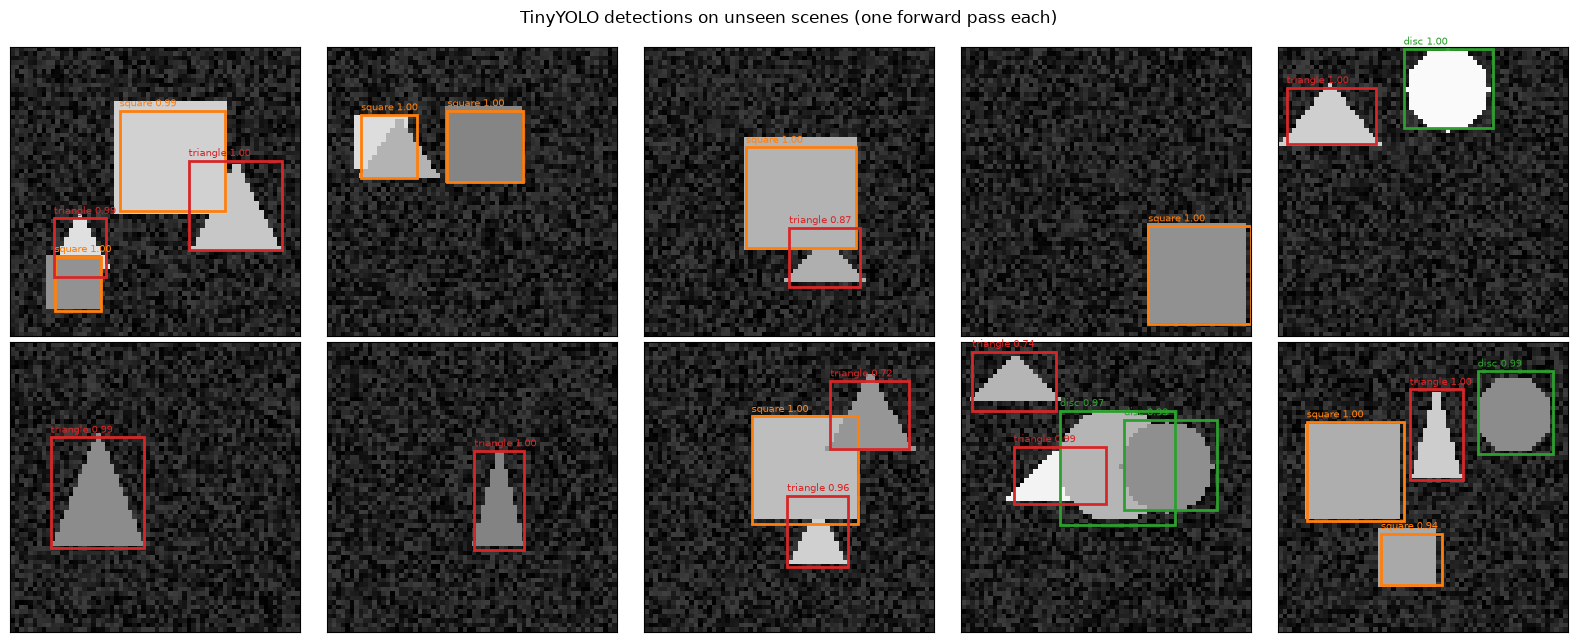

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for a, img, d in zip(axes.flat, x[:10], dets[:10]):
    a.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    for k, s_, b in d:
        a.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=f"C{k + 1}", lw=2))
        a.text(b[0], b[1] - 1, f"{CLASSES[k]} {s_:.2f}", color=f"C{k + 1}", fontsize=7)
    a.set_xticks([]); a.set_yticks([])
plt.suptitle("TinyYOLO detections on unseen scenes (one forward pass each)"); plt.tight_layout(); plt.show()

## Takeaways
- **Detection as one regression:** each grid cell predicts objectness, box and class at once. No proposals, no per-region classifier, so a single forward pass is enough for real time.
- **The supporting machinery** is the same in every modern detector: IoU to compare boxes, NMS to remove duplicates, and mean average precision (mAP) to evaluate.
- **Known YOLOv1 weaknesses** (one object per cell, coarse grid, small objects) were fixed by anchors and multi-scale feature maps (YOLOv2/v3, SSD, Feature Pyramid Networks). DETR (2020) replaced grids and NMS with a Transformer that predicts a *set* of boxes, and segmentation models such as Mask R-CNN (2017) and SAM (2023) extended detection to pixel masks.